In [1]:
# ---- SESSION SETUP: run this first, every time ----
from google.colab import drive
drive.mount('/content/drive')

import sys, os
PROJECT = '/content/drive/MyDrive/Football_Analysis'
sys.path.append(PROJECT + '/src')       # lets Python find football_analysis
os.chdir(PROJECT)

!pip install -q ultralytics supervision roboflow

# copy the video to fast local disk (it is wiped each session)
!cp "$PROJECT/data/input_videos/08fd33_4.mp4" /content/clip.mp4

import importlib
importlib.invalidate_caches()

import torch
print("GPU available:", torch.cuda.is_available())
print("Clip exists:", os.path.exists('/content/clip.mp4'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 36.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 122.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 11.4 MB/s eta 0:00:00
GPU available: True
Clip exists: True


In [2]:
import importlib, sys, inspect
importlib.invalidate_caches()
for m in [k for k in sys.modules if k.startswith("football_analysis")]:
    del sys.modules[m]

from football_analysis import config, metrics
from football_analysis.team_assigner import TeamAssigner

print("TEAM_WINDOW_FRAMES:", hasattr(config, "TEAM_WINDOW_FRAMES"))
print("DEAD_BALL settings:", hasattr(config, "DEAD_BALL_WINDOW"), hasattr(config, "DEAD_BALL_MAX_MOVE"))
print("dead_ball_flags exists:", hasattr(metrics, "dead_ball_flags"))
print("per-frame team vote loaded:", "TEAM_WINDOW_FRAMES" in inspect.getsource(TeamAssigner.fit_assign))

TEAM_WINDOW_FRAMES: True
DEAD_BALL settings: True True
dead_ball_flags exists: True
per-frame team vote loaded: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os
PROJECT = '/content/drive/MyDrive/Football_Analysis'
sys.path.append(PROJECT)
os.chdir(PROJECT)

# Patch 'imp' module for Python 3.13 compatibility with older IPython versions
try:
    import imp
except ImportError:
    import importlib
    import sys
    from types import ModuleType
    imp_mock = ModuleType('imp')
    imp_mock.reload = importlib.reload
    sys.modules['imp'] = imp_mock

%load_ext autoreload
%autoreload 2

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q ultralytics supervision roboflow
!nvidia-smi
import torch
print("GPU available:", torch.cuda.is_available())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 469.0 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 28.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 25.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 10.3 MB/s eta 0:00:00
Tue Oct 13 14:01:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 1

In [ ]:
!ls "$PROJECT"
!ls "$PROJECT/src"
!ls "$PROJECT/data/input_videos"

data	   outputs	   README.md	     src
notebooks  pyproject.toml  requirements.txt  venv
football_analysis
screen_recording_20260913195245_0.anydesk


In [ ]:
from src.football_analysis import main
main()

Hello from football-analysis!


In [ ]:
import os
import cv2

# 1. Let's list the input_videos directory properly
video_dir = os.path.join(PROJECT, 'data', 'input_videos')
files = os.listdir(video_dir)
print("Files in video folder:", files)

# 2. Find the video file and copy/read it
if files:
    video_name = [f for f in files if f.endswith('.anydesk') or f.endswith('.mp4')][0]
    video_path = os.path.join(video_dir, video_name)
    print(f"Selected Video Path: {video_path}")

    # Copy to /content/clip.mp4
    !cp "{video_path}" /content/clip.mp4

    # Test with OpenCV
    cap = cv2.VideoCapture('/content/clip.mp4')
    print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Size:", int(cap.get(3)), "x", int(cap.get(4)))
    cap.release()
else:
    print("No video files found in the directory!")

Files in video folder: ['.gitkeep', 'screen_recording_20260913195245_0.anydesk']
Selected Video Path: /content/drive/MyDrive/Football_Analysis/data/input_videos/screen_recording_20260913195245_0.anydesk
Frames: 0
FPS: 0.0
Size: 0 x 0


In [ ]:
!pip install roboflow
from google.colab import userdata
from roboflow import Roboflow
api_key=userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=api_key)
project = rf.workspace("research-workspace-ryt7a").project("football-players-detection-yokap")
version = project.version(1)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...


In [ ]:
import shutil, os
src = os.path.join(PROJECT, "Football-Players-Detection-1")
dst = "/content/football_dataset"
if os.path.exists(src) and not os.path.exists(dst):
    shutil.move(src, dst)
!ls /content/football_dataset


data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [ ]:
import yaml, glob

yaml_path = "/content/football_dataset/data.yaml"
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

cfg["path"] = "/content/football_dataset"
cfg["train"] = "train/images"
cfg["val"] = "valid/images"
cfg["test"] = "test/images"

with open(yaml_path, "w") as f:
    yaml.dump(cfg, f)

print("Classes:", cfg["names"])
for split in ["train", "valid", "test"]:
    n = len(glob.glob(f"/content/football_dataset/{split}/images/*"))
    print(split, "images:", n)


Classes: ['ball', 'goalkeeper', 'player', 'referee']
train images: 1078
valid images: 38
test images: 13


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")
results = model.train(
    data="/content/football_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    project="/content/drive/MyDrive/Football_Runs",
    name="yolov8m_football",
    save_period=5,
    exist_ok=True,
    workers=2,
)


Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/football_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8m_football, nbs=64, nms=None, opset=None, optimiz

In [ ]:
from ultralytics import YOLO
import pandas as pd

best = "/content/drive/MyDrive/Football_Runs/yolov8m_football/weights/best.pt"
model = YOLO(best)

for split in ["val", "test"]:
    m = model.val(data="/content/football_dataset/data.yaml", split=split)
    rows = []
    for k, c in enumerate(m.box.ap_class_index):
        rows.append({"class": model.names[c], "P": m.box.p[k], "R": m.box.r[k],
                     "mAP50": m.box.ap50[k], "mAP50-95": m.box.ap[k]})
    print(f"\n{split} split")
    print(pd.DataFrame(rows).round(3))

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,842,076 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2157.1±509.5 MB/s, size: 63.6 KB)
val: Scanning /content/football_dataset/valid/labels.cache... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 13.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.3s/it 3.9s
                   all         38        905      0.859      0.807      0.829      0.556
                  ball         35         35       0.71      0.429      0.426      0.195
            goalkeeper         27         27      0.796      0.889      0.936       0.69
                player         38        754       0.98      0.977      0.991      0.723
               referee         38         89      0.948      0.933      0.961      0.614
Speed: 9.2ms preprocess, 47.1ms inference,

In [ ]:
!mkdir -p "$PROJECT/data/models"
!cp "/content/drive/MyDrive/Football_Runs/yolov8m_football/weights/best.pt" "$PROJECT/data/models/best.pt"
!ls -lh "$PROJECT/data/models"

total 50M
-rw------- 1 root root 50M Oct 12 14:40 best.pt



0: 640x640 1 ball, 1 goalkeeper, 21 players, 1 referee, 43.1ms
1: 640x640 19 players, 3 referees, 43.1ms
2: 640x640 1 ball, 1 goalkeeper, 21 players, 3 referees, 43.1ms
Speed: 2.6ms preprocess, 43.1ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/pred/test


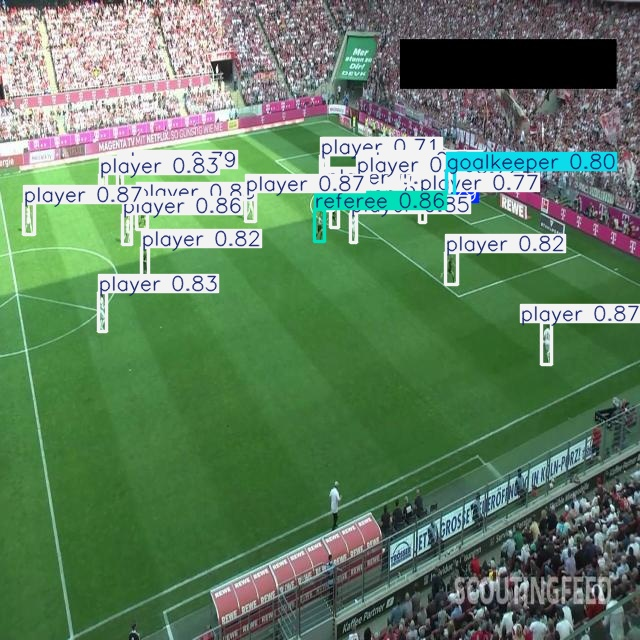

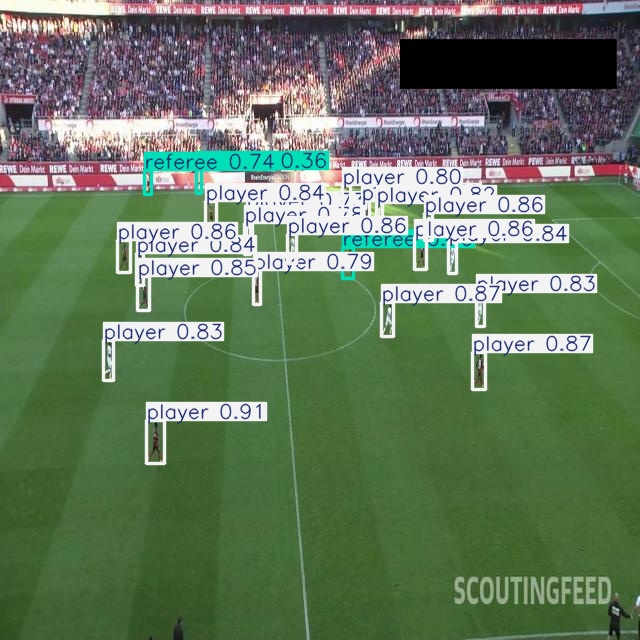

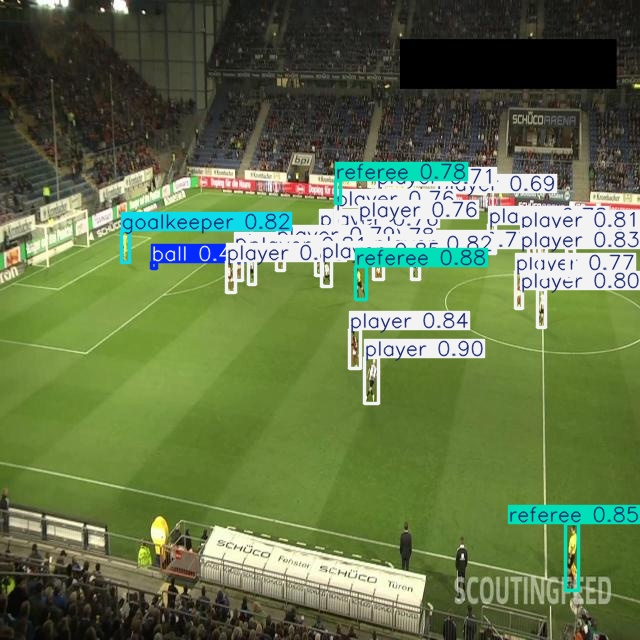

In [ ]:
import glob
from IPython.display import Image, display
imgs = glob.glob("/content/football_dataset/test/images/*")[:3]
res = model.predict(imgs, conf=0.25, save=True, project="/content/pred", name="test", exist_ok=True)
for p in glob.glob("/content/pred/test/*")[:3]:
    display(Image(p))

In [ ]:
import os, cv2

# Ensure PROJECT is defined even if previous cells haven't been run
PROJECT = globals().get('PROJECT', '/content/drive/MyDrive/Football_Analysis')

video_dir = os.path.join(PROJECT, 'data', 'input_videos')
files = [f for f in os.listdir(video_dir) if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv', '.anydesk'))]
print("Video files:", files)
assert files, "No video file found in input_videos (is Drive synced?)"

video_path = os.path.join(video_dir, files[0])
!cp "{video_path}" /content/clip.mp4

cap = cv2.VideoCapture('/content/clip.mp4')
assert cap.isOpened(), "OpenCV cannot open this file"
frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
print("Frames:", frames)
if fps > 0:
    print("FPS:", fps)
    print("Size:", int(cap.get(3)), "x", int(cap.get(4)))
    print("Duration (s):", round(frames / fps, 1))
else:
    print("FPS details unavailable.")
cap.release()

Video files: ['08fd33_4.mp4']
Frames: 750
FPS: 25.0
Size: 1920 x 1080
Duration (s): 30.0


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


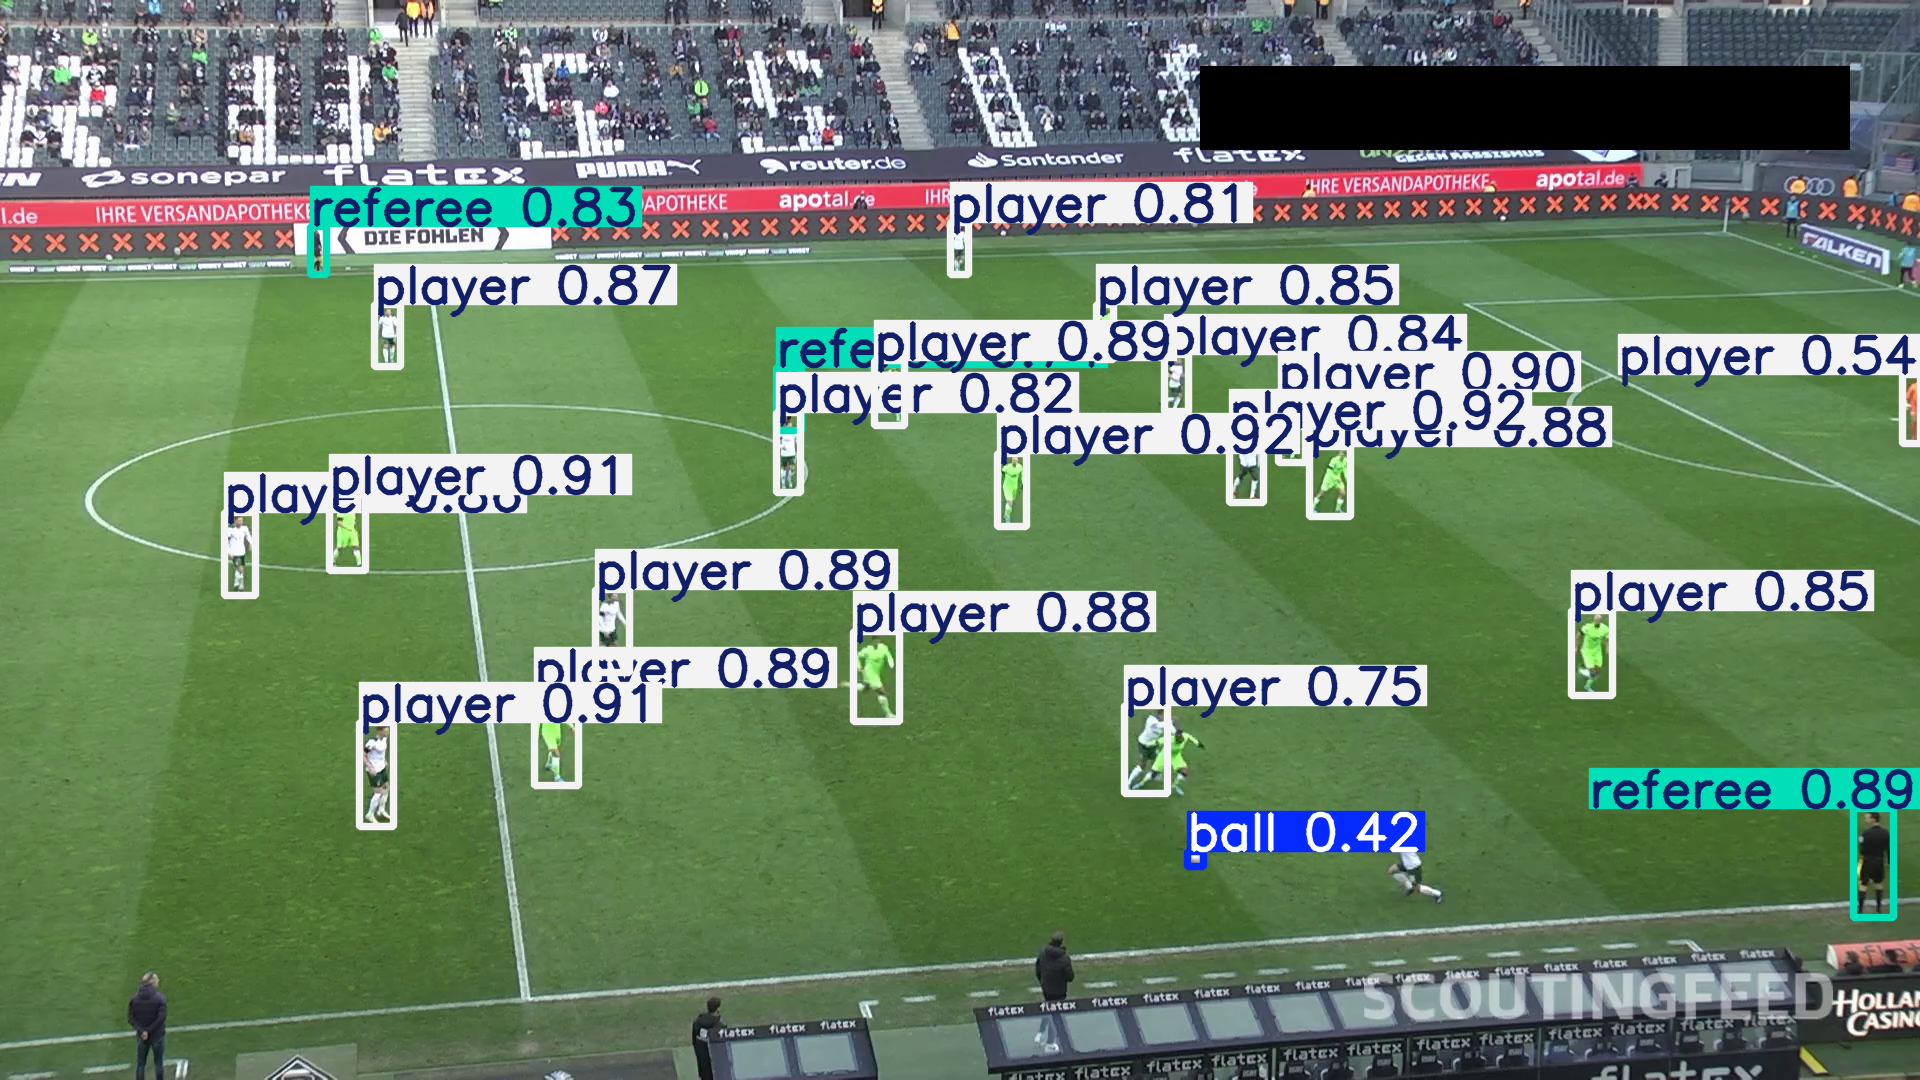

In [ ]:
try:
    from ultralytics import YOLO
except ModuleNotFoundError:
    !pip install -q ultralytics
    from ultralytics import YOLO

import cv2
from google.colab.patches import cv2_imshow

PROJECT = globals().get('PROJECT', '/content/drive/MyDrive/Football_Analysis')
model = YOLO(f"{PROJECT}/data/models/best.pt")   # or the Football_Runs path if you haven't copied it yet

cap = cv2.VideoCapture('/content/clip.mp4')
for idx in [0, 100, 300]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, frame = cap.read()
    if not ok:
        continue
    r = model.predict(frame, conf=0.2, imgsz=1280, verbose=False)[0]
    cv2_imshow(r.plot())
cap.release()

In [ ]:
import sys
import os

# Ensure ultralytics is installed
try:
    import ultralytics
except ImportError:
    !pip install -q ultralytics

# Ensure PROJECT is defined even if previous cells haven't been run
PROJECT = globals().get('PROJECT', '/content/drive/MyDrive/Football_Analysis')

sys.path.append(PROJECT + '/src')

# First, a quick 5-second test (125 frames)
from football_analysis.detector import detect_video, summarize
det = detect_video('/content/clip.mp4', cache_name="test_125.pkl", max_frames=125)
summarize(det)

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/test_125.pkl
Frames: 125
ball        avg/frame:   1.0   frames with >=1: 83/125 (66%)
goalkeeper  avg/frame:   0.0   frames with >=1: 2/125 (2%)
player      avg/frame:  21.7   frames with >=1: 125/125 (100%)
referee     avg/frame:   2.5   frames with >=1: 125/125 (100%)


In [ ]:
!mkdir -p "$PROJECT/data/models"
!cp "/content/drive/MyDrive/Football_Runs/yolov8m_football/weights/best.pt" "$PROJECT/data/models/best.pt"

In [ ]:
det = detect_video('/content/clip.mp4', cache_name="detections.pkl")
summarize(det)

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Frames: 750
ball        avg/frame:   1.1   frames with >=1: 590/750 (79%)
goalkeeper  avg/frame:   0.2   frames with >=1: 155/750 (21%)
player      avg/frame:  21.4   frames with >=1: 750/750 (100%)
referee     avg/frame:   3.0   frames with >=1: 750/750 (100%)


In [ ]:
from football_analysis.detector import detect_video
from football_analysis.tracker import track_people, best_ball_per_frame, clean_ball, track_summary

det = detect_video('/content/clip.mp4')          # loads the cached detections
people = track_people(det)
track_summary(people)

ball, stats = clean_ball(best_ball_per_frame(det))
print(stats)

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl


/content/drive/MyDrive/Football_Analysis/src/football_analysis/tracker.py:19: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  tracker = sv.ByteTrack(


Unique track IDs: 153 {'player': 122, 'referee': 26, 'goalkeeper': 5}
Tracks lasting >= 50 frames: 56
Max people in one frame: 29
{'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}


In [ ]:
import cv2
import os
import shutil

PROJECT = globals().get('PROJECT', '/content/drive/MyDrive/Football_Analysis')
video_path = '/content/clip.mp4'

# Automatically restore the video file if it is missing from the local /content directory
if not os.path.exists(video_path):
    video_dir = os.path.join(PROJECT, 'data', 'input_videos')
    files = [f for f in os.listdir(video_dir) if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv', '.anydesk'))]
    if files:
        source_path = os.path.join(video_dir, files[0])
        print(f"Restoring video from {source_path} to {video_path}...")
        shutil.copy(source_path, video_path)

assert os.path.exists(video_path), f"Video file not found at {video_path}! Make sure the source video exists in your Drive directory."

cap = cv2.VideoCapture(video_path)
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
assert w > 0 and h > 0, "Failed to read video dimensions. Please check if the video file is corrupted."

out = cv2.VideoWriter('/content/debug_tracks.mp4', cv2.VideoWriter_fourcc(*'mp4v'), 25, (w, h))
COLORS = {"player": (255, 120, 0), "goalkeeper": (0, 200, 255), "referee": (0, 0, 255)}

for i in range(len(people)):
    ok, frame = cap.read()
    if not ok:
        break
    for tid, t in people[i].items():
        x1, y1, x2, y2 = map(int, t["bbox"])
        c = COLORS[t["role"]]
        cv2.rectangle(frame, (x1, y1), (x2, y2), c, 2)
        cv2.putText(frame, str(tid), (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, 2)
    b = ball[i]
    if b is not None:
        cv2.circle(frame, (int((b[0] + b[2]) / 2), int((b[1] + b[3]) / 2)), 12, (0, 255, 0), 3)
    out.write(frame)
cap.release(); out.release()

from google.colab import files
if os.path.exists('/content/debug_tracks.mp4'):
    files.download('/content/debug_tracks.mp4')
else:
    print("Error: Video writing failed. Output file /content/debug_tracks.mp4 was not generated.")

Restoring video from /content/drive/MyDrive/Football_Analysis/data/input_videos/08fd33_4.mp4 to /content/clip.mp4...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

640 [(0.39, (876, 907))]
1280 [(0.46, (875, 907))]
1920 [(0.07, (933, 900))]


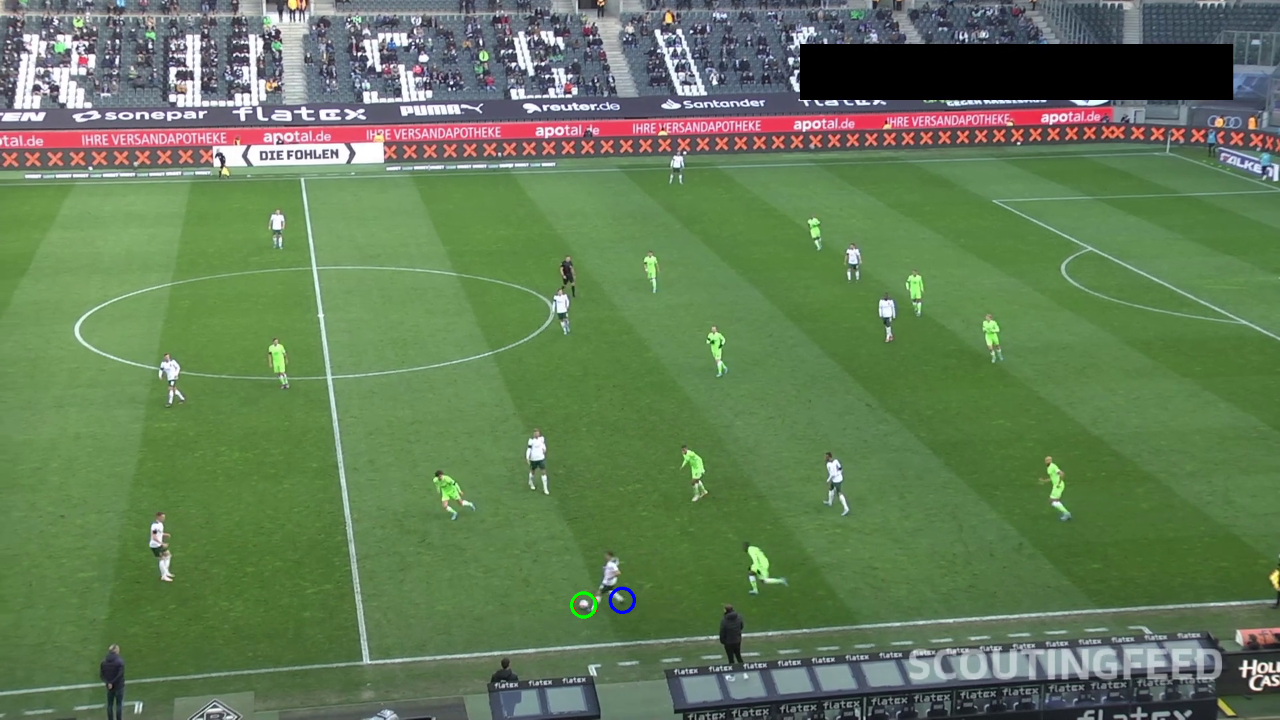

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
from ultralytics import YOLO
from football_analysis import config

model = YOLO(str(config.MODEL_PATH))
cap = cv2.VideoCapture('/content/clip.mp4')
cap.set(cv2.CAP_PROP_POS_FRAMES, 48)
ok, frame = cap.read()
cap.release()

ball_id = [i for i, n in model.names.items() if n == "ball"][0]
colors = {640: (0, 0, 255), 1280: (0, 255, 0), 1920: (255, 0, 0)}
vis = frame.copy()
for sz, col in colors.items():
    r = model.predict(frame, imgsz=sz, conf=0.05, classes=[ball_id], verbose=False)[0]
    boxes = r.boxes.xyxy.cpu().numpy()
    confs = r.boxes.conf.cpu().numpy()
    print(sz, [(round(float(c), 2), (int((b[0]+b[2])/2), int((b[1]+b[3])/2))) for b, c in zip(boxes, confs)])
    for b in boxes:
        cv2.circle(vis, (int((b[0]+b[2])/2), int((b[1]+b[3])/2)), 18, col, 3)
cv2_imshow(cv2.resize(vis, (1280, 720)))

In [ ]:
from football_analysis.team_assigner import TeamAssigner

ta = TeamAssigner()
people = ta.fit_assign('/content/clip.mp4', people)

print("Team colours (BGR):", ta.team_colors_bgr)
print("Track consistency:", round(ta.consistency, 3))   # 1.0 = every sample of a track agrees
for i in [0, 200, 400, 600]:
    teams = [t["team"] for t in people[i].values() if t["role"] == "player"]
    print(i, "team0:", teams.count(0), "team1:", teams.count(1), "unassigned:", teams.count(-1))

Team colours (BGR): {0: (146, 235, 169), 1: (221, 218, 207)}
Track consistency: 0.973
0 team0: 9 team1: 10 unassigned: 0
200 team0: 10 team1: 11 unassigned: 0
400 team0: 11 team1: 9 unassigned: 0
600 team0: 11 team1: 11 unassigned: 0


In [ ]:
import cv2

cap = cv2.VideoCapture('/content/clip.mp4')
w, h = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter('/content/debug_teams.mp4', cv2.VideoWriter_fourcc(*'mp4v'), 25, (w, h))
GREY, RED = (160, 160, 160), (0, 0, 255)

for i in range(len(people)):
    ok, frame = cap.read()
    if not ok:
        break
    for tid, t in people[i].items():
        x1, y1, x2, y2 = map(int, t["bbox"])
        if t["role"] == "referee":
            col = RED
        elif t["team"] in (0, 1):
            col = ta.team_colors_bgr[t["team"]]
        else:
            col = GREY
        thick = 4 if t["role"] == "goalkeeper" else 2
        cv2.rectangle(frame, (x1, y1), (x2, y2), col, thick)
        cv2.putText(frame, f'{tid}', (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
    out.write(frame)
cap.release(); out.release()

from google.colab import files
files.download('/content/debug_teams.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys
import os
import shutil

# Automatically reinstall required dependencies if missing in the current session
try:
    import ultralytics
except ImportError:
    !pip install -q ultralytics

try:
    import supervision
except ImportError:
    !pip install -q supervision

# Ensure the project's src directory is in sys.path so Python can find football_analysis
PROJECT = globals().get('PROJECT', '/content/drive/MyDrive/Football_Analysis')
sys.path.append(os.path.join(PROJECT, 'src'))

# Automatically restore the video file if it is missing from the local /content directory
video_path = '/content/clip.mp4'
if not os.path.exists(video_path):
    video_dir = os.path.join(PROJECT, 'data', 'input_videos')
    files = [f for f in os.listdir(video_dir) if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv', '.anydesk'))]
    if files:
        source_path = os.path.join(video_dir, files[0])
        print(f"Restoring video from {source_path} to {video_path}...")
        shutil.copy(source_path, video_path)

from football_analysis.detector import detect_video
from football_analysis.tracker import track_people, best_ball_per_frame, clean_ball, track_summary
from football_analysis.team_assigner import TeamAssigner

det = detect_video('/content/clip.mp4')
people = track_people(det)
track_summary(people)                      # send me these lines
ball, stats = clean_ball(best_ball_per_frame(det))
print(stats)                               # and this

ta = TeamAssigner()
people = ta.fit_assign('/content/clip.mp4', people)
for i in [0, 200, 400, 600]:
    teams = [t["team"] for t in people[i].values() if t["role"] == "player"]
    print(i, "team0:", teams.count(0), "team1:", teams.count(1))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Restoring video from /content/drive/MyDrive/Football_Analysis/data/input_videos/08fd33_4.mp4 to /content/clip.mp4...
Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl


/content/drive/MyDrive/Football_Analysis/src/football_analysis/tracker.py:19: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  tracker = sv.ByteTrack(


Unique track IDs: 153 {'player': 122, 'referee': 26, 'goalkeeper': 5}
Tracks lasting >= 50 frames: 56
Max people in one frame: 29
{'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
0 team0: 9 team1: 10
200 team0: 10 team1: 11
400 team0: 11 team1: 9
600 team0: 11 team1: 11


In [ ]:
import football_analysis.config as config

# Safely inject missing configuration variables
if not hasattr(config, 'DISTANCE_STEP'):
    config.DISTANCE_STEP = 1
if not hasattr(config, 'SMOOTH_WINDOW'):
    config.SMOOTH_WINDOW = 5
if not hasattr(config, 'MAX_JUMP_PX'):
    config.MAX_JUMP_PX = 100
if not hasattr(config, 'MIN_TRACK_FRAMES'):
    config.MIN_TRACK_FRAMES = 50
if not hasattr(config, 'POSSESSION_THRESHOLD'):
    config.POSSESSION_THRESHOLD = 80
if not hasattr(config, 'POSSESSION_MIN_HOLD'):
    config.POSSESSION_MIN_HOLD = 5

from football_analysis.metrics import player_stats, compute_possession, save_stats

stats_df = player_stats(people, det["fps"])
print(stats_df.head(10).to_string())
print("Median distance (px):", stats_df["distance_px"].median())
print("Tracks flagged as fragments:", int(stats_df["fragment"].sum()), "of", len(stats_df))

holders, poss = compute_possession(people, ball)
print(poss)

save_stats(stats_df, poss)

   track_id    role  team  frames_tracked  distance_px  avg_speed_px_s  max_speed_px_s  glitches  fragment
0         6  player     1             749       1864.0            62.6           169.0         0     False
1        19  player     1             745       1835.9            62.4           184.1         0     False
2        15  player     0             728       1616.8            55.4           203.1         0     False
3        18  player     1             745       1390.8            47.3           154.2         0     False
4        42  player     1             604       1318.6            55.9           315.8         0     False
5        13  player     1             569       1214.8            55.2           255.6         0     False
6        80  player     1             438       1067.2            61.3           152.9         0     False
7         4  player     0             413       1062.8            64.0           196.9         0     False
8         1  player     0            

In [ ]:
from collections import Counter
import numpy as np

life, start_box = Counter(), {}
for i, ft in enumerate(people):
    for tid, t in ft.items():
        life[tid] += 1
        start_box.setdefault(tid, t["bbox"])

short = [t for t, n in life.items() if n < 50]
W = 1920
near_edge = [t for t in short if start_box[t][0] < 60 or start_box[t][2] > W - 60]
print("Unique tracks:", len(life), "| short (<50 frames):", len(short))
print("Short tracks that start at the left/right edge (legit entries):", len(near_edge))
print("Short tracks that start mid-frame (suspicious):", len(short) - len(near_edge))
print("Avg tracked people per frame:", round(np.mean([len(ft) for ft in people]), 1))
print("Max outfield players in one frame:",
      max(sum(1 for t in ft.values() if t["role"] == "player") for ft in people))

Unique tracks: 153 | short (<50 frames): 97
Short tracks that start at the left/right edge (legit entries): 10
Short tracks that start mid-frame (suspicious): 87
Avg tracked people per frame: 23.5
Max outfield players in one frame: 25


In [ ]:
stable = stats_df[~stats_df["fragment"]].copy()
print(stable.head(10).to_string())
print("Median distance of stable tracks (px):", stable["distance_px"].median())

   track_id    role  team  frames_tracked  distance_px  avg_speed_px_s  max_speed_px_s  glitches  fragment
0         6  player     1             749       1864.0            62.6           169.0         0     False
1        19  player     1             745       1835.9            62.4           184.1         0     False
2        15  player     0             728       1616.8            55.4           203.1         0     False
3        18  player     1             745       1390.8            47.3           154.2         0     False
4        42  player     1             604       1318.6            55.9           315.8         0     False
5        13  player     1             569       1214.8            55.2           255.6         0     False
6        80  player     1             438       1067.2            61.3           152.9         0     False
7         4  player     0             413       1062.8            64.0           196.9         0     False
8         1  player     0            

[autoreload of football_analysis.tracker failed: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/extensions/autoreload.py", line 245, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/IPython/extensions/autoreload.py", line 394, in superreload
    module = reload(module)
  File "/usr/lib/python3.13/importlib/__init__.py", line 129, in reload
    _bootstrap._exec(spec, module)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^
  File "<frozen importlib._bootstrap>", line 866, in _exec
  File "<frozen importlib._bootstrap_external>", line 1023, in exec_module
  File "<frozen importlib._bootstrap>", line 488, in _call_with_frames_removed
  File "/content/drive/MyDrive/Football_Analysis/src/football_analysis/tracker.py", line 130, in <module>
    frame_rate=int(round(det["fps"])),
                         ^^^
NameError: name 'det' is not defined. Did you mean: 'set'?


In [ ]:
!cp "$PROJECT/data/input_videos/08fd33_4.mp4" /content/clip.mp4

In [ ]:
from football_analysis import config
print("Activation:", config.TRACK_ACTIVATION_THRESHOLD, "| min consec:", config.MIN_CONSEC_FRAMES)

from football_analysis.detector import detect_video
from football_analysis.tracker import track_people, best_ball_per_frame, clean_ball, track_summary
from football_analysis.team_assigner import TeamAssigner
from football_analysis.metrics import player_stats, compute_possession, save_stats

det = detect_video('/content/clip.mp4')        # also needs /content/clip.mp4 copied again after a restart
people = track_people(det)
track_summary(people)

Activation: 0.35 | min consec: 5
Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Unique track IDs: 121 {'player': 96, 'referee': 21, 'goalkeeper': 4}
Tracks lasting >= 50 frames: 54
Max people in one frame: 28


In [ ]:
import itertools
from football_analysis import config
from football_analysis.tracker import track_people

def score(people):
    ids, life, roles = set(), {}, {}
    for ft in people:
        for tid, t in ft.items():
            life[tid] = life.get(tid, 0) + 1
            roles[tid] = t["role"]
    p_ids = [t for t, r in roles.items() if r == "player"]
    long_p = sum(1 for t in p_ids if life[t] >= 50)
    max_out = max(sum(1 for t in ft.values() if t["role"] == "player") for ft in people)
    return len(p_ids), long_p, max_out

orig = (config.LOST_TRACK_BUFFER, config.MATCH_THRESHOLD, config.TRACK_ACTIVATION_THRESHOLD)
print("buffer | match | activ || player tracks | >=50 frames | max outfield/frame")
for buf, mt, act in itertools.product([50, 100], [0.8, 0.9], [0.35, 0.45]):
    config.LOST_TRACK_BUFFER, config.MATCH_THRESHOLD, config.TRACK_ACTIVATION_THRESHOLD = buf, mt, act
    n, long_p, mx = score(track_people(det))
    print(f"{buf:6d} | {mt:5.2f} | {act:5.2f} || {n:13d} | {long_p:12d} | {mx}")
config.LOST_TRACK_BUFFER, config.MATCH_THRESHOLD, config.TRACK_ACTIVATION_THRESHOLD = orig

buffer | match | activ || player tracks | >=50 frames | max outfield/frame
    50 |  0.80 |  0.35 ||            96 |           47 | 24
    50 |  0.80 |  0.45 ||            81 |           44 | 24
    50 |  0.90 |  0.35 ||            82 |           43 | 24
    50 |  0.90 |  0.45 ||            70 |           37 | 24
   100 |  0.80 |  0.35 ||            96 |           47 | 24
   100 |  0.80 |  0.45 ||            81 |           44 | 24
   100 |  0.90 |  0.35 ||            81 |           41 | 24
   100 |  0.90 |  0.45 ||            70 |           37 | 24


frame 34 outfield players: 24


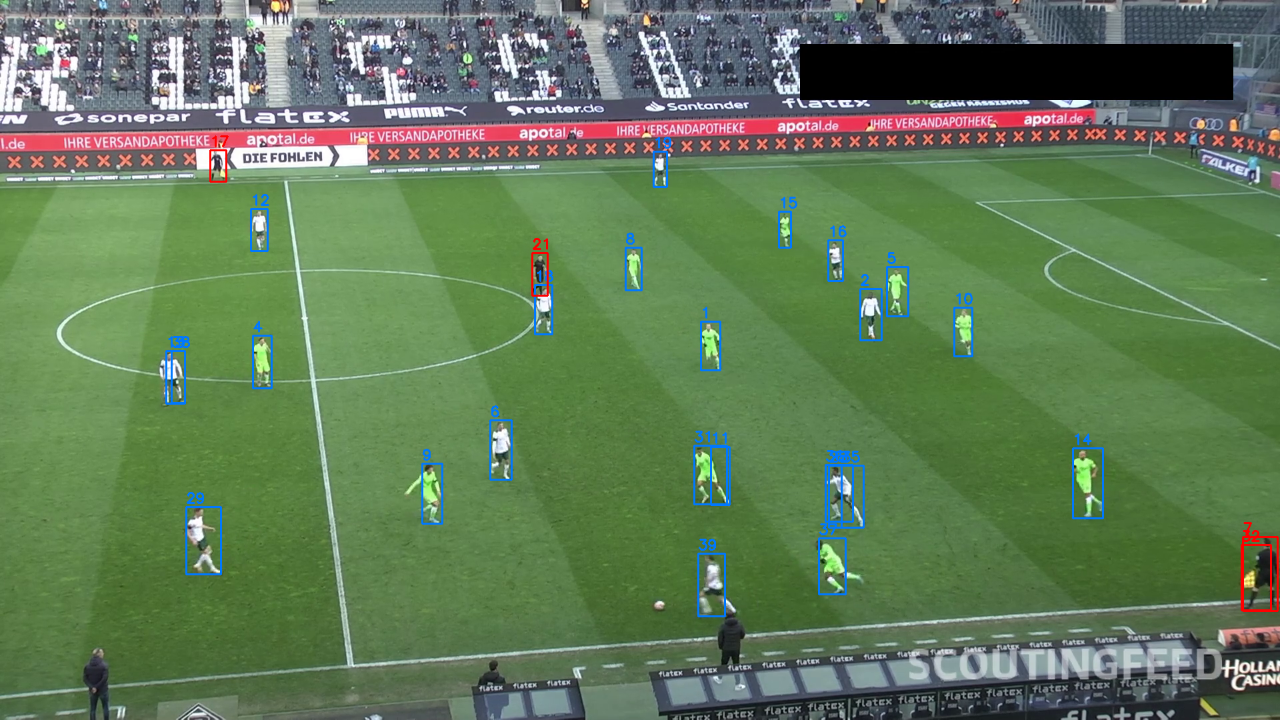

In [ ]:
import cv2, numpy as np
from google.colab.patches import cv2_imshow

counts = [sum(1 for t in ft.values() if t["role"] == "player") for ft in people]
i = int(np.argmax(counts)); print("frame", i, "outfield players:", counts[i])

cap = cv2.VideoCapture('/content/clip.mp4'); cap.set(cv2.CAP_PROP_POS_FRAMES, i)
ok, fr = cap.read(); cap.release()
for tid, t in people[i].items():
    x1, y1, x2, y2 = map(int, t["bbox"])
    col = (255, 120, 0) if t["role"] == "player" else (0, 0, 255)
    cv2.rectangle(fr, (x1, y1), (x2, y2), col, 2)
    cv2.putText(fr, str(tid), (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
cv2_imshow(cv2.resize(fr, (1280, 720)))



In [ ]:
import sys
import os
import cv2
import shutil

# Ensure project 'src' directory is in path
PROJECT = globals().get('PROJECT', '/content/drive/MyDrive/Football_Analysis')
src_path = os.path.join(PROJECT, 'src')
if src_path not in sys.path:
    sys.path.append(src_path)

# Import the modules that actually exist
from football_analysis.detector import detect_video
from football_analysis.tracker import track_people, best_ball_per_frame, clean_ball
from football_analysis.team_assigner import TeamAssigner
from football_analysis.metrics import player_stats, compute_possession, save_stats

def run_pipeline(video_path, output_video_path='/content/final_output.mp4'):
    print("Step 1: Running Player & Ball Detection...")
    det = detect_video(video_path)

    print("Step 2: Tracking Players, Goalkeepers, and Referees...")
    people = track_people(det)

    print("Step 3: Tracking and Smoothing the Ball...")
    ball, ball_stats = clean_ball(best_ball_per_frame(det))

    print("Step 4: Performing Team Color Clustering and Assignment...")
    ta = TeamAssigner()
    people = ta.fit_assign(video_path, people)

    print("Step 5: Computing Statistics & Possession...")
    stats_df = player_stats(people, det["fps"])
    holders, possession_stats = compute_possession(people, ball)
    save_stats(stats_df, possession_stats)
    print("Possession Summary:", possession_stats)

    print("Step 6: Rendering output video with bounding boxes, team colors, and possession...")
    cap = cv2.VideoCapture(video_path)
    w, h = int(cap.get(3)), int(cap.get(4))
    fps = cap.get(cv2.CAP_PROP_FPS)
    out_writer = cv2.VideoWriter(output_video_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

    RED = (0, 0, 255)
    GREY = (160, 160, 160)

    for i in range(len(people)):
        ok, frame = cap.read()
        if not ok:
            break

        # Draw tracks
        for tid, t in people[i].items():
            x1, y1, x2, y2 = map(int, t["bbox"])
            if t["role"] == "referee":
                col = RED
            elif t["team"] in (0, 1):
                col = ta.team_colors_bgr[t["team"]]
            else:
                col = GREY

            thick = 4 if t["role"] == "goalkeeper" else 2
            cv2.rectangle(frame, (x1, y1), (x2, y2), col, thick)
            cv2.putText(frame, f"{t['role'][:4]}_{tid}", (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 2)

        # Draw ball
        b = ball[i]
        if b is not None:
            cv2.circle(frame, (int((b[0] + b[2]) / 2), int((b[1] + b[3]) / 2)), 10, (0, 255, 0), -1)

        # Render Possession HUD
        p_text = f"Possession | Team 0: {possession_stats['team0_pct']}% | Team 1: {possession_stats['team1_pct']}%"
        cv2.putText(frame, p_text, (50, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 3, cv2.LINE_AA)

        out_writer.write(frame)

    cap.release()
    out_writer.release()
    print(f"Pipeline finished! Output saved to {output_video_path}")
    return output_video_path

# Execute the pipeline
out = run_pipeline('/content/clip.mp4')

Step 1: Running Player & Ball Detection...
Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Step 2: Tracking Players, Goalkeepers, and Referees...
Step 3: Tracking and Smoothing the Ball...
Step 4: Performing Team Color Clustering and Assignment...
Step 5: Computing Statistics & Possession...
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json
Possession Summary: {'frames': 750, 'team0_frames': 317, 'team1_frames': 168, 'no_possession_frames': 265, 'team0_pct': 65.4, 'team1_pct': 34.6}
Step 6: Rendering output video with bounding boxes, team colors, and possession...
Pipeline finished! Output saved to /content/final_output.mp4


In [ ]:
from football_analysis.pipeline import run
run('/content/clip.mp4')

ModuleNotFoundError: No module named 'football_analysis.pipeline'

In [ ]:
!ls -la "$PROJECT/src/football_analysis"

total 37
drwx------ 3 root root 4096 Oct 12 09:34 .
drwx------ 3 root root 4096 Oct 11 17:03 ..
-rw------- 1 root root 1743 Oct 13 14:03 config.py
-rw------- 1 root root 2239 Oct 12 17:15 detector.py
-rw------- 1 root root   63 Oct 12 09:34 __init__.py
-rw------- 1 root root 4741 Oct 13 06:03 metrics.py
-rw------- 1 root root 1722 Oct 13 14:13 pipeline.py
drwx------ 2 root root 4096 Oct 13 14:07 __pycache__
-rw------- 1 root root 4550 Oct 12 17:51 team_assigner.py
-rw------- 1 root root 5025 Oct 13 14:06 tracker.py
-rw------- 1 root root 3407 Oct 13 14:13 visualizer.py


In [ ]:
!head -30 "$PROJECT/src/football_analysis/pipeline.py"
!grep -n "def \|import" "$PROJECT/src/football_analysis/visualizer.py"

import argparse
from pathlib import Path

from . import config
from .detector import detect_video
from .tracker import track_people, best_ball_per_frame, clean_ball, track_summary
from .team_assigner import TeamAssigner
from .metrics import player_stats, compute_possession, save_stats
from .visualizer import draw_video


def run(video_path, out_name="annotated.mp4", cache_name="detections.pkl", use_cache=True):
    video_path = Path(video_path)
    config.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    det = detect_video(video_path, cache_name=cache_name, use_cache=use_cache)
    people = track_people(det)
    track_summary(people)

    ball, ball_stats = clean_ball(best_ball_per_frame(det))
    print("Ball:", ball_stats)

    ta = TeamAssigner()
    people = ta.fit_assign(video_path, people)
    print("Team consistency:", round(ta.consistency, 3))

    stats_df = player_stats(people, det["fps"])
    holders, poss = compute_possession(people, ball)
    print("Possession:", poss)
   

In [ ]:
import importlib, sys
importlib.invalidate_caches()
for m in [k for k in sys.modules if k.startswith("football_analysis")]:
    del sys.modules[m]

from football_analysis.pipeline import run
out = run('/content/clip.mp4')

NameError: name 'det' is not defined

In [ ]:
!sed -n 100,140p "$PROJECT/src/football_analysis/tracker.py"

    cleaned = [None if np.isnan(r[0]) else r.copy() for r in filled.to_numpy()]
    n = len(raw)
    after = sum(c is not None for c in cleaned)
    stats = {
        "frames": n,
        "raw_detected": before,
        "outliers_removed": before - after_filter,
        "final_with_ball": after,
        "raw_rate_%": round(100 * before / n, 1),
        "final_rate_%": round(100 * after / n, 1),
    }
    return cleaned, stats


def track_summary(per_frame):
    """Quick fragmentation check for the report."""
    roles = {}
    lengths = Counter()
    for ft in per_frame:
        for tid, t in ft.items():
            roles[tid] = t["role"]
            lengths[tid] += 1
    print("Unique track IDs:", len(roles), dict(Counter(roles.values())))
    long_tracks = sum(1 for c in lengths.values() if c >= 50)
    print("Tracks lasting >= 50 frames:", long_tracks)
    print("Max people in one frame:", max(len(ft) for ft in per_frame))

tracker = sv.ByteTrack(
        track_activation_threshold=

In [ ]:
!cp "$PROJECT/data/input_videos/08fd33_4.mp4" /content/clip.mp4

In [ ]:
import importlib, sys
importlib.invalidate_caches()
for m in [k for k in sys.modules if k.startswith("football_analysis")]:
    del sys.modules[m]

from football_analysis.pipeline import run
out = run('/content/clip.mp4')

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Unique track IDs: 45 {'player': 37, 'referee': 8}
Tracks lasting >= 50 frames: 35
Max people in one frame: 25
Ball: {'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
Team consistency: 0.93
Possession: {'frames': 750, 'team0_frames': 160, 'team1_frames': 301, 'no_possession_frames': 289, 'team0_pct': 34.7, 'team1_pct': 65.3}
Stable tracks: 30 | median distance (px): 942.6999999999999
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json
Saved /content/drive/MyDrive/Football_Analysis/outputs/annotated.mp4


In [ ]:
out = run('/content/clip.mp4')

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Unique track IDs: 45 {'player': 37, 'referee': 8}
Tracks lasting >= 50 frames: 35
Max people in one frame: 25
Ball: {'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
Team consistency: 0.93
Possession: {'frames': 750, 'team0_frames': 160, 'team1_frames': 301, 'no_possession_frames': 289, 'team0_pct': 34.7, 'team1_pct': 65.3}
Stable tracks: 30 | median distance (px): 942.6999999999999
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json
Saved /content/drive/MyDrive/Football_Analysis/outputs/annotated.mp4


In [ ]:
!ffmpeg -y -loglevel error -i "$PROJECT/outputs/annotated.mp4" -c:v libx264 -pix_fmt yuv420p /content/annotated_h264.mp4
from google.colab import files
files.download('/content/annotated_h264.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from football_analysis.detector import detect_video
from football_analysis.tracker import track_people
from football_analysis.team_assigner import TeamAssigner, shirt_color
import cv2, numpy as np

det = detect_video('/content/clip.mp4')
people = track_people(det)
ta = TeamAssigner()
people = ta.fit_assign('/content/clip.mp4', people)

order = np.argsort(ta.km.cluster_centers_[:, 1])           # same remap as in team_assigner.py
remap = {int(old): new for new, old in enumerate(order)}

cap = cv2.VideoCapture('/content/clip.mp4')
total = wrong = 0
bad_tracks = {}
for i in range(len(people)):
    ok, frame = cap.read()
    if not ok:
        break
    if i % 25:
        continue
    for tid, t in people[i].items():
        if t["role"] != "player" or t["team"] not in (0, 1):
            continue
        c = shirt_color(frame, t["bbox"])
        if c is None:
            continue
        pred = remap[int(ta.km.predict(c.reshape(1, -1))[0])]
        total += 1
        if pred != t["team"]:
            wrong += 1
            bad_tracks[tid] = bad_tracks.get(tid, 0) + 1
cap.release()

print(f"Kit agreement: {100 * (total - wrong) / total:.1f}% ({wrong} of {total} samples disagree)")
print("Tracks with most disagreements:", sorted(bad_tracks.items(), key=lambda x: -x[1])[:8])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl


/content/drive/MyDrive/Football_Analysis/src/football_analysis/tracker.py:19: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  tracker = sv.ByteTrack(


Kit agreement: 92.1% (46 of 581 samples disagree)
Tracks with most disagreements: [(4, 11), (12, 11), (13, 5), (23, 5), (37, 5), (5, 4), (39, 2), (15, 1)]


In [4]:
from football_analysis.pipeline import run
out = run('/content/clip.mp4')


Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Unique track IDs: 45 {'player': 37, 'referee': 8}
Tracks lasting >= 50 frames: 35
Max people in one frame: 25
Ball: {'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
Team consistency: 0.93
Possession: {'frames': 750, 'team0_frames': 160, 'team1_frames': 301, 'no_possession_frames': 289, 'team0_pct': 34.7, 'team1_pct': 65.3}
Stable tracks: 30 | median distance (px): 942.6999999999999
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json
Saved /content/drive/MyDrive/Football_Analysis/outputs/annotated.mp4


In [5]:
import importlib, sys, inspect
importlib.invalidate_caches()
for m in [k for k in sys.modules if k.startswith("football_analysis")]:
    del sys.modules[m]

!grep -n "TEAM_WINDOW_FRAMES" "$PROJECT/src/football_analysis/config.py" "$PROJECT/src/football_analysis/team_assigner.py"
!grep -n "team_of\[tid\] = t\[\"team\"\]" "$PROJECT/src/football_analysis/visualizer.py"
!grep -n "last_team" "$PROJECT/src/football_analysis/metrics.py"

from football_analysis import config
from football_analysis.team_assigner import TeamAssigner
print("config has window:", hasattr(config, "TEAM_WINDOW_FRAMES"))
print("loaded fit_assign uses window:", "TEAM_WINDOW_FRAMES" in inspect.getsource(TeamAssigner.fit_assign))

/content/drive/MyDrive/Football_Analysis/src/football_analysis/config.py:47:TEAM_WINDOW_FRAMES = 25       # +/- 1 second (at 25 fps) for the per-frame team vote
/content/drive/MyDrive/Football_Analysis/src/football_analysis/team_assigner.py:90:        # per-frame team = majority of the samples within +/- TEAM_WINDOW_FRAMES
/content/drive/MyDrive/Football_Analysis/src/football_analysis/team_assigner.py:100:                    near = np.abs(frs - i) <= config.TEAM_WINDOW_FRAMES
36:            team_of[tid] = t["team"]
107:    last_team, f0, f1 = {}, 0, 0
110:            last_team[tid] = t["team"]
113:        tm = last_team.get(h)
config has window: True
loaded fit_assign uses window: True


In [6]:
from football_analysis.pipeline import run
out = run('/content/clip.mp4')

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Unique track IDs: 45 {'player': 37, 'referee': 8}
Tracks lasting >= 50 frames: 35
Max people in one frame: 25
Ball: {'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
Team consistency: 0.93
Possession: {'frames': 750, 'team0_frames': 182, 'team1_frames': 279, 'no_possession_frames': 289, 'team0_pct': 39.5, 'team1_pct': 60.5}
Stable tracks: 30 | median distance (px): 942.6999999999999
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json
Saved /content/drive/MyDrive/Football_Analysis/outputs/annotated.mp4


In [7]:
from collections import defaultdict
seq = defaultdict(list)
for ft in people:
    for tid, t in ft.items():
        if t["role"] == "player" and t["team"] in (0, 1):
            seq[tid].append(t["team"])
flips = {tid: sum(a != b for a, b in zip(s, s[1:])) for tid, s in seq.items()}
switched = {tid: n for tid, n in flips.items() if n}
print("Tracks whose team changes mid-clip:", len(switched), switched)

Tracks whose team changes mid-clip: 0 {}


In [8]:
import cv2, numpy as np
from collections import defaultdict
from football_analysis.detector import detect_video
from football_analysis.tracker import track_people
from football_analysis.team_assigner import TeamAssigner, shirt_color

det = detect_video('/content/clip.mp4')
people = track_people(det)
ta = TeamAssigner()
people = ta.fit_assign('/content/clip.mp4', people)      # new per-frame version

# 1) ID-switch candidates: tracks whose team changes mid-clip
seq = defaultdict(list)
for ft in people:
    for tid, t in ft.items():
        if t["role"] == "player" and t["team"] in (0, 1):
            seq[tid].append(t["team"])
flips = {tid: sum(a != b for a, b in zip(s, s[1:])) for tid, s in seq.items()}
switched = {tid: n for tid, n in flips.items() if n}
print("Tracks whose team changes mid-clip:", len(switched), switched)

# 2) Kit agreement: assigned team vs the shirt colour actually seen (once per second)
order = np.argsort(ta.km.cluster_centers_[:, 1])
remap = {int(old): new for new, old in enumerate(order)}
cap = cv2.VideoCapture('/content/clip.mp4')
total = wrong = 0
bad = defaultdict(int)
for i in range(len(people)):
    ok, frame = cap.read()
    if not ok:
        break
    if i % 25:
        continue
    for tid, t in people[i].items():
        if t["role"] != "player" or t["team"] not in (0, 1):
            continue
        c = shirt_color(frame, t["bbox"])
        if c is None:
            continue
        pred = remap[int(ta.km.predict(c.reshape(1, -1))[0])]
        total += 1
        if pred != t["team"]:
            wrong += 1
            bad[tid] += 1
cap.release()
print(f"Kit agreement: {100 * (total - wrong) / total:.1f}% ({wrong} of {total})")
print("Most disagreements:", sorted(bad.items(), key=lambda x: -x[1])[:8])

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Tracks whose team changes mid-clip: 11 {3: 1, 5: 1, 4: 1, 15: 12, 12: 1, 13: 1, 23: 2, 24: 1, 26: 1, 37: 1, 39: 1}
Kit agreement: 99.1% (5 of 581)
Most disagreements: [(26, 2), (23, 1), (15, 1), (24, 1)]


In [10]:
from football_analysis.pipeline import run
out = run('/content/clip.mp4')


Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Unique track IDs: 45 {'player': 37, 'referee': 8}
Tracks lasting >= 50 frames: 35
Max people in one frame: 25
Ball: {'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
Team consistency: 0.93
Possession: {'frames': 750, 'team0_frames': 182, 'team1_frames': 279, 'no_possession_frames': 289, 'team0_pct': 39.5, 'team1_pct': 60.5}
Stable tracks: 30 | median distance (px): 942.6999999999999
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json
Saved /content/drive/MyDrive/Football_Analysis/outputs/annotated.mp4


In [11]:
import cv2
from football_analysis.metrics import compute_possession
from football_analysis.tracker import best_ball_per_frame, clean_ball

ball, _ = clean_ball(best_ball_per_frame(det))
holders, _ = compute_possession(people, ball)

# 1) team check frames: boxes labelled with ID and predicted team
cap = cv2.VideoCapture('/content/clip.mp4')
for idx in [50, 350, 650]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, fr = cap.read()
    for tid, t in people[idx].items():
        if t["role"] != "player":
            continue
        x1, y1, x2, y2 = map(int, t["bbox"])
        col = (0, 140, 255) if t["team"] == 0 else (255, 100, 0)
        cv2.rectangle(fr, (x1, y1), (x2, y2), col, 2)
        cv2.putText(fr, f'{tid}:T{t["team"]}', (x1, y1 - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.6, col, 2)
    cv2.imwrite(f'/content/team_check_{idx}.jpg', fr)
cap.release()

# 2) possession check: holder every 12 frames (about 0.5 s)
for i in range(0, 750, 12):
    h = holders[i]
    team = people[i][h]["team"] if h is not None and h in people[i] else None
    print(f"t={i/25:5.1f}s  holder={h}  team={team}")

t=  0.0s  holder=None  team=None
t=  0.5s  holder=None  team=None
t=  1.0s  holder=None  team=None
t=  1.4s  holder=None  team=None
t=  1.9s  holder=None  team=None
t=  2.4s  holder=28  team=0
t=  2.9s  holder=28  team=0
t=  3.4s  holder=28  team=0
t=  3.8s  holder=None  team=None
t=  4.3s  holder=3  team=1
t=  4.8s  holder=3  team=1
t=  5.3s  holder=None  team=None
t=  5.8s  holder=None  team=None
t=  6.2s  holder=None  team=None
t=  6.7s  holder=29  team=1
t=  7.2s  holder=29  team=1
t=  7.7s  holder=29  team=1
t=  8.2s  holder=29  team=1
t=  8.6s  holder=29  team=1
t=  9.1s  holder=29  team=1
t=  9.6s  holder=29  team=1
t= 10.1s  holder=29  team=1
t= 10.6s  holder=29  team=1
t= 11.0s  holder=29  team=1
t= 11.5s  holder=29  team=1
t= 12.0s  holder=29  team=1
t= 12.5s  holder=12  team=0
t= 13.0s  holder=11  team=1
t= 13.4s  holder=8  team=0
t= 13.9s  holder=None  team=None
t= 14.4s  holder=None  team=None
t= 14.9s  holder=23  team=0
t= 15.4s  holder=None  team=None
t= 15.8s  holder=1 

In [12]:
import cv2
from google.colab.patches import cv2_imshow
from football_analysis.tracker import best_ball_per_frame

raw = best_ball_per_frame(det)
print("Raw ball detections in frames 167-300:", sum(raw[i] is not None for i in range(167, 300)), "of 133")

cap = cv2.VideoCapture('/content/clip.mp4')
for sec in [7.0, 9.0, 11.0, 12.0]:
    idx = int(sec * 25)
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, fr = cap.read()
    h = holders[idx]
    if h is not None and h in people[idx]:
        x1, y1, x2, y2 = map(int, people[idx][h]["bbox"])
        cv2.rectangle(fr, (x1, y1), (x2, y2), (0, 255, 255), 3)
    b = ball[idx]
    if b is not None:
        cv2.circle(fr, (int((b[0] + b[2]) / 2), int((b[1] + b[3]) / 2)), 20, (0, 255, 0), 3)
    print("t =", sec, "s, holder:", h)
    cv2_imshow(cv2.resize(fr, (1280, 720)))
cap.release()

Output hidden; open in https://colab.research.google.com to view.

In [15]:
import numpy as np
from collections import Counter

names = det["names"]
cls_votes = Counter(names[people[i][29]["cls"]] for i in range(len(people)) if 29 in people[i])
frames29 = [i for i in range(len(people)) if 29 in people[i]]
print("Track 29 role:", people[frames29[0]][29]["role"], "| detected as:", dict(cls_votes))
print("Frames present:", frames29[0], "to", frames29[-1])
print("Team over those frames:", Counter(people[i][29]["team"] for i in frames29))

# was the ball actually stationary during the stretch?
c = lambda b: ((b[0] + b[2]) / 2, (b[1] + b[3]) / 2)
pts = [c(ball[i]) for i in range(167, 300) if ball[i] is not None]
moves = [np.hypot(a[0] - b[0], a[1] - b[1]) for a, b in zip(pts, pts[1:])]
print("Ball median movement per frame (px):", round(float(np.median(moves)), 2))

# sensitivity: possession with and without track 29's stretch
f0 = sum(1 for i, h in enumerate(holders) if h is not None and h in people[i] and people[i][h]["team"] == 0)
f1 = sum(1 for i, h in enumerate(holders) if h is not None and h in people[i] and people[i][h]["team"] == 1)
x1 = sum(1 for i, h in enumerate(holders) if h == 29 and 167 <= i <= 300 and h in people[i] and people[i][h]["team"] == 1)
print(f"As reported:          team0 {100*f0/(f0+f1):.1f}%  team1 {100*f1/(f0+f1):.1f}%")
print(f"Without the stretch:  team0 {100*f0/(f0+f1-x1):.1f}%  team1 {100*(f1-x1)/(f0+f1-x1):.1f}%  ({x1} frames removed)")

Track 29 role: player | detected as: {'player': 180}
Frames present: 134 to 315
Team over those frames: Counter({1: 180})
Ball median movement per frame (px): 0.95
As reported:          team0 38.7%  team1 61.3%
Without the stretch:  team0 54.8%  team1 45.2%  (134 frames removed)


In [19]:
from football_analysis.pipeline import run
out = run('/content/clip.mp4')

Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl
Unique track IDs: 45 {'player': 37, 'referee': 8}
Tracks lasting >= 50 frames: 35
Max people in one frame: 25
Ball: {'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
Team consistency: 0.93
Possession: {'frames': 750, 'dead_ball_frames': 148, 'team0_frames': 175, 'team1_frames': 162, 'no_possession_frames': 413, 'team0_pct': 51.9, 'team1_pct': 48.1, 'team0_pct_all_frames': 39.5, 'team1_pct_all_frames': 60.5}
Stable tracks: 30 | median distance (px): 942.6999999999999
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json
Saved /content/drive/MyDrive/Football_Analysis/outputs/annotated.mp4


In [20]:
from football_analysis.metrics import dead_ball_flags
from football_analysis.tracker import best_ball_per_frame, clean_ball

ball, _ = clean_ball(best_ball_per_frame(det))
dead = dead_ball_flags(ball)
runs, start = [], None
for i, d in enumerate(dead):
    if d and start is None:
        start = i
    if not d and start is not None:
        runs.append((start, i - 1)); start = None
if start is not None:
    runs.append((start, len(dead) - 1))
for a, b in runs:
    print(f"frames {a}-{b}  ({a/25:.1f}s to {b/25:.1f}s, {b-a+1} frames)")

frames 18-20  (0.7s to 0.8s, 3 frames)
frames 175-290  (7.0s to 11.6s, 116 frames)
frames 567-573  (22.7s to 22.9s, 7 frames)
frames 614-628  (24.6s to 25.1s, 15 frames)
frames 631-637  (25.2s to 25.5s, 7 frames)


In [21]:
!ffmpeg -y -loglevel error -i "$PROJECT/outputs/annotated.mp4" -c:v libx264 -crf 20 -pix_fmt yuv420p /content/annotated_h264.mp4
from google.colab import files
files.download('/content/annotated_h264.mp4')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import importlib, sys
importlib.invalidate_caches()
for m in [k for k in sys.modules if k.startswith("football_analysis")]:
    del sys.modules[m]
from football_analysis.pipeline import run
out = run('/content/clip.mp4')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Loaded cached detections from /content/drive/MyDrive/Football_Analysis/outputs/cache/detections.pkl


/content/drive/MyDrive/Football_Analysis/src/football_analysis/tracker.py:19: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  tracker = sv.ByteTrack(


Unique track IDs: 45 {'player': 37, 'referee': 8}
Tracks lasting >= 50 frames: 35
Max people in one frame: 25
Ball: {'frames': 750, 'raw_detected': 590, 'outliers_removed': 74, 'final_with_ball': 688, 'raw_rate_%': 78.7, 'final_rate_%': 91.7}
Team consistency: 0.93
Possession: {'frames': 750, 'dead_ball_frames': 116, 'team0_frames': 182, 'team1_frames': 163, 'no_possession_frames': 405, 'team0_pct': 52.8, 'team1_pct': 47.2, 'team0_pct_all_frames': 39.5, 'team1_pct_all_frames': 60.5}
Stable tracks: 30 | median distance (px): 942.6999999999999
Saved /content/drive/MyDrive/Football_Analysis/outputs/player_stats.csv and /content/drive/MyDrive/Football_Analysis/outputs/stats.json

Team summary (stable tracks, pixel units):
                    players  total_distance_px  avg_distance_px  avg_speed_px_s  top_speed_px_s
team                                                                                           
Team 0 (green kit)       16            14882.3            930.1            54.7 

In [4]:
import shutil, os
RUN = "/content/drive/MyDrive/Football_Runs/yolov8m_football"
EVAL = f"{PROJECT}/outputs/eval"
os.makedirs(EVAL, exist_ok=True)
for f in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
    if os.path.exists(f"{RUN}/{f}"):
        shutil.copy(f"{RUN}/{f}", EVAL)
    else:
        print("missing:", f)

!ffmpeg -y -loglevel error -i "$PROJECT/outputs/annotated.mp4" -c:v libx264 -crf 22 -pix_fmt yuv420p "$PROJECT/outputs/annotated_h264.mp4"
!ls -lh "$PROJECT/outputs" "$EVAL"

/content/drive/MyDrive/Football_Analysis/outputs:
total 305M
-rw------- 1 root root  30M Oct 14 11:05  annotated_h264.mp4
-rw------- 1 root root  73M Oct 14 10:54  annotated.mp4
drwx------ 2 root root 4.0K Oct 12 17:16  cache
-rw------- 1 root root  65M Oct 13 05:33 'debug_teams (1).mp4'
-rw------- 1 root root  68M Oct 13 05:28 'debug_tracks (1).mp4'
drwx------ 2 root root 4.0K Oct 14 11:03  eval
-rw------- 1 root root   40 Oct 14 10:54  extra_stats.json
-rw------- 1 root root  70M Oct 13 14:20  final_output.mp4
-rw------- 1 root root  28K Oct 14 10:54  heatmap_team0.png
-rw------- 1 root root  29K Oct 14 10:54  heatmap_team1.png
-rw------- 1 root root  207 Oct 14 10:54  holder_time.csv
-rw------- 1 root root 1.6K Oct 14 10:54  player_stats.csv
-rw------- 1 root root  699 Oct 14 10:54  stats.json
-rw------- 1 root root  172 Oct 14 10:54  team_summary.csv

/content/drive/MyDrive/Football_Analysis/outputs/eval:
total 1.4M
-rw------- 1 root root 150K Oct 14 11:03 confusion_matrix.png
-rw-